# Robustez · Fase 2

Comprueba si los resultados de la fase 2 (`07_fase2`: efectos **entre categorías**) **se mantienen** cuando se cambia una decisión del análisis por otra razonable. El modelo principal reproduce `07_fase2` tal como está; cada prueba cambia **una sola cosa**.

**Qué pruebas se hacen y de dónde salen** (lista de robustez de `metodologia.md` §4 y decisión D‑29; no se inventa ninguna):

| Código | Prueba | Qué se cambia | Por qué (decisión) | Tipo |
|---|---|---|---|---|
| `principal` | Modelo principal | Nada: reproduce `07_fase2` | — | Referencia |
| `efectos_fijos_semana` | Efectos fijos de semana | Mes → semana | D‑16, opción (b2) | Especificación |
| `sin_diciembre` | Sin diciembre | Se excluye diciembre de 2016 | `metodologia.md` §4.1 | Corte de tiempo |
| `terremoto_corto` | Ventana corta del terremoto | Se excluye hasta el 16‑05‑2016 y se recalculan **todos** los rezagos (SKU y diarios) | D‑09 | Corte de tiempo |
| `intensidad_log` | Intensidad en logaritmo | La promoción de otras categorías se mide como $\log(1+N_{kt})$ (número de SKUs en promoción) en vez de proporción | D‑07, `metodologia.md` §4.3 | Medición |
| `sin_resto` | Sin la variable de resto | Se saca `p__RESTO` y sus rezagos | D‑29 ("modelo sin resto") | Especificación |
| `skus_todo_el_periodo` | SKUs presentes todo el período | Solo SKUs presentes los 590 días | D‑24 | Submuestra |
| `placebo_adelanto` | Placebo con adelantos | Se agrega la promoción de cada otra categoría en los **3 días siguientes** | `metodologia.md` fase 2: "placebo" | Falsificación |
| — | Corrección al 10 % | Benjamini‑Hochberg al 10 % (sin reestimar) | D‑15 | Parámetro |

**Ya hecha en otro notebook:** la comparación con **ventas agregadas por categoría** (`metodologia.md` §4.5) está en `09_fase3_trafico`, Paso 10. Aquí no se repite.

**Qué no se hace y por qué** (limitación): cotas de la imputación de promociones (D‑25) y otra tienda, porque exigen rehacer la preparación de datos.

| | |
|---|---|
| **Entrada** | `panel_t44_sku_dia.parquet`, `exposiciones_t44_sku_dia.parquet`, `calendario_t44.csv`, `exposicion_t44_categorias_dia.csv`, `exposicion_t44_resto_por_objetivo.csv` (los mismos de `07_fase2`) e `intensidad_t44_categoria_dia.csv` (para recalcular intensidades); `fase2_coeficientes.csv` solo para verificar, si existe |
| **Tablas** (en `resultados/tablas/`) | `robustez_fase2_coeficientes.csv`, `robustez_fase2_consistencia.csv`, `robustez_fase2_resumen.csv`, `robustez_fase2_nuevos_significativos.csv`, `robustez_fase2_placebo.csv`, `robustez_fase2_bh10.csv`, `robustez_fase2_muestras.csv`, `robustez_fase2_diagnostico.csv` |
| **Figura** | `robustez_fase2_dispersion.png` |
| **No modifica** | ningún notebook ni archivo existente: todas las salidas empiezan con `robustez_fase2_` |



## Guía rápida: qué se busca en la fase 2

En la fase 2 el modelo principal **no encontró ningún par de categorías con efecto significativo** tras la corrección por comparaciones múltiples (el valor p corregido más bajo fue 0,057). Por eso la robustez aquí responde dos preguntas:

1. **¿Ese "sin efecto detectable" se mantiene?** Si con otra especificación razonable aparecen pares significativos, hay que reportarlos: la conclusión depende de esa decisión.
2. **¿Las direcciones (signos) de los efectos son estables?** Aunque no sean significativos, si los signos cambian mucho entre especificaciones, los números del mapa de calor (fase 4) son poco confiables; si se mantienen, la tendencia general (por ejemplo, más pares negativos que positivos) es más creíble.

| Columna | Lectura |
|---|---|
| `mismo_signo` | El efecto apunta en la misma dirección que en el principal. |
| `misma_conclusion` | Sinergia / canibalización / sin efecto: la misma clasificación que el principal. |
| `diferencia_pp` | Cuánto cambia el efecto de +10 pp, en puntos porcentuales (no se calcula para `intensidad_log`, que mide en otra escala). |
| `dentro_ic_principal` | El nuevo valor cae dentro del intervalo del principal. |

**El placebo** usa la promoción **futura** de las otras categorías: no puede causar las ventas de hoy. Si sale significativa, hay confusión temporal o promociones anunciadas (`metodologia.md`, fase 2).

## Paso 1. Librerías y parámetros

Los parámetros del modelo son **copias exactas** de `07_fase2`.

In [1]:
# ------------------------------------------------------------------------------------------------------------
# Este notebook aplica las pruebas de robustez de la metodología (metodologia.md §4, D-29) a la fase 2
# (07_fase2): efectos fijos de semana, sin diciembre, ventana corta del terremoto, intensidad en logaritmo,
# sin resto, SKUs presentes todo el período, placebo con adelantos y Benjamini-Hochberg al 10 %.
# ------------------------------------------------------------------------------------------------------------
# Implementación: NachaJavi (con asistencia de Claude), a partir de 07_fase2 y 03_exposiciones
# Fecha de versión: 2026-11-11
# ------------------------------------------------------------------------------------------------------------

# Librerías
# ------------------------------------------------------------------------------------------------------------
import os
import re
import warnings

import numpy as np
import pandas as pd
import pyfixest as pf
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests

# pyfixest avisa cuando un control de calendario de uno o dos días queda sin error estándar y cuando elimina
# SKUs con una sola observación (igual que en 07_fase2)
warnings.filterwarnings("ignore", message="invalid value encountered in sqrt")
warnings.filterwarnings("ignore", message=".*singleton.*")

# Parámetros del modelo (copiados de 07_fase2)
# ------------------------------------------------------------------------------------------------------------
categorias = [
    "BEVERAGES", "GROCERY I", "CLEANING", "DAIRY", "BREAD/BAKERY", "LIQUOR,WINE,BEER",
    "MEATS", "POULTRY", "DELI", "PRODUCE",
]
categorias_programa = ["MEATS", "POULTRY", "DELI", "PRODUCE"]
bloques = ["", "_l1_3", "_l4_6"]
nombre_bloque = {"": "dia", "_l1_3": "l1_3", "_l4_6": "l4_6"}
regresores_fase1 = [f"{v}{b}" for v in ["onpromotion", "promo_clase_otros", "promo_cat_otras_clases"] for b in bloques]
controles_calendario = [
    "dia_libre", "adicional", "dia_laboral_recuperado", "evento_comercial", "evento_otro", "dia_pago", "post_pago",
]
variable_dependiente = "unit_sales_ppml"   # D-08, D-20
efectos_fijos = "item_nbr + dow + mes"     # D-16
agrupamiento = "item_nbr + semana"         # D-15
delta_p = 0.10                             # efectos de proporciones: +10 puntos porcentuales del surtido
alfa = 0.05                                # D-15: Benjamini-Hochberg al 5 %


def nombre_columna(familia: str) -> str:
    """
    Esta función convierte el nombre de una familia en el nombre de su columna de intensidad (igual que
    03_exposiciones y 07_fase2), por ejemplo 'LIQUOR,WINE,BEER' -> 'p__LIQUOR_WINE_BEER'.

    :param familia:     el nombre de la familia.
    :return:            el nombre de la columna.
    """
    return "p__" + re.sub(r"[^A-Z0-9]+", "_", familia.upper()).strip("_")


columna_categoria = {c: nombre_columna(c) for c in categorias}

# Parámetros de las pruebas de robustez
# ------------------------------------------------------------------------------------------------------------
especificaciones = {
    "principal":            "Modelo principal (07_fase2)",
    "efectos_fijos_semana": "Efectos fijos de semana en vez de mes (D-16)",
    "sin_diciembre":        "Sin diciembre de 2016",
    "terremoto_corto":      "Ventana del terremoto hasta el 16-05-2016 (D-09)",
    "intensidad_log":       "Intensidad de otras categorías como log(1+N) (D-07)",
    "sin_resto":            "Sin la variable de resto (D-29)",
    "skus_todo_el_periodo": "Solo SKUs presentes los 590 días (D-24)",
    "placebo_adelanto":     "Placebo: promoción de otras categorías en los 3 días siguientes",
}
efectos_fijos_semana = "item_nbr + dow + semana"            # D-16, opción (b2)
mes_excluido = 12                                           # diciembre
bloques_dias = {"l1_3": [1, 2, 3], "l4_6": [4, 5, 6]}       # D-14, los de 03_exposiciones
bloques_sku = {"l1_3": [1, 2, 3], "l4_6": [4, 5, 6]}
alfa_alternativo = 0.10                                     # D-15

# Rutas
# ------------------------------------------------------------------------------------------------------------
ruta_procesados = os.path.join("..", "data", "procesados")
ruta_tablas = os.path.join("resultados", "tablas")
ruta_figuras = os.path.join("resultados", "figuras")
os.makedirs(ruta_tablas, exist_ok=True)
os.makedirs(ruta_figuras, exist_ok=True)
prefijo = "robustez_fase2"
archivo_principal_07 = os.path.join(ruta_tablas, "fase2_coeficientes.csv")   # solo para verificar

## Paso 2. Importar los datos

Los mismos archivos de `07_fase2`, más `intensidad_t44_categoria_dia.csv`, que tiene el número de SKUs activos y en promoción de cada categoría y día. Se necesita para recalcular la intensidad con la ventana corta del terremoto, la versión en logaritmo y el resto.

In [2]:
panel = pd.read_parquet(os.path.join(ruta_procesados, "panel_t44_sku_dia.parquet"))
exposiciones = pd.read_parquet(os.path.join(ruta_procesados, "exposiciones_t44_sku_dia.parquet"))
calendario = pd.read_csv(os.path.join(ruta_procesados, "calendario_t44.csv"), parse_dates=["date"])
exposicion_categorias = pd.read_csv(os.path.join(ruta_procesados, "exposicion_t44_categorias_dia.csv"), parse_dates=["date"])
exposicion_resto = pd.read_csv(os.path.join(ruta_procesados, "exposicion_t44_resto_por_objetivo.csv"), parse_dates=["date"])
intensidad = pd.read_csv(os.path.join(ruta_procesados, "intensidad_t44_categoria_dia.csv"), parse_dates=["date"])
intensidad["family"] = intensidad["family"].astype(str)

# Cifras de control (las mismas de 07_fase2)
assert len(panel) == len(exposiciones), "el panel y las exposiciones deben tener las mismas filas"
assert len(calendario) == len(exposicion_categorias) == 590, "las tablas diarias no tienen 590 días"
assert set(columna_categoria.values()) <= set(exposicion_categorias.columns), "falta alguna categoría del núcleo"

# Índice de día de operación, ventana corta del terremoto y SKUs presentes todo el período (como Robustez_Fase1)
calendario = calendario.sort_values("date").reset_index(drop=True)
calendario["t"] = np.arange(len(calendario))
calendario["ventana_terremoto_corta"] = calendario["terremoto"].astype(bool)
assert calendario.loc[calendario["ventana_terremoto_corta"], "ventana_terremoto"].all(), "la ventana corta debe estar dentro de la larga"
assert (exposicion_categorias["date"].to_numpy() == calendario["date"].to_numpy()).all(), "las fechas diarias no están alineadas"
dias_por_sku = panel.groupby("item_nbr").size()
skus_todo_el_periodo = set(dias_por_sku.index[dias_por_sku == len(calendario)])

# Categorías que forman el "resto": las categorías fuente de 03_exposiciones que no están en el núcleo
familia_de_columna = {nombre_columna(f): f for f in intensidad["family"].unique()}
columnas_fuente = [c for c in exposicion_categorias.columns if c.startswith("p__") and not c.endswith(("_l1_3", "_l4_6", "_f1_3"))]
fuentes_resto = [familia_de_columna[c] for c in columnas_fuente if familia_de_columna[c] not in categorias]

print(f"panel: {len(panel):,} SKU-días | calendario: {len(calendario)} días | intensidad: {len(intensidad):,} categoría-días")
print(f"ventana del terremoto: larga = {calendario['ventana_terremoto'].sum()} días, corta = {calendario['ventana_terremoto_corta'].sum()} días")
print(f"días de diciembre: {(calendario['date'].dt.month == mes_excluido).sum()} | SKUs presentes los 590 días: {len(skus_todo_el_periodo):,}")
print(f"categorías del resto ({len(fuentes_resto)}): {fuentes_resto}")

panel: 1,935,758 SKU-días | calendario: 590 días | intensidad: 18,551 categoría-días
ventana del terremoto: larga = 46 días, corta = 31 días
días de diciembre: 30 | SKUs presentes los 590 días: 2,122
categorías del resto (12): ['HOME AND KITCHEN II', 'PERSONAL CARE', 'HOME CARE', 'FROZEN FOODS', 'HOME AND KITCHEN I', 'BEAUTY', 'SEAFOOD', 'EGGS', 'PREPARED FOODS', 'AUTOMOTIVE', 'PET SUPPLIES', 'SCHOOL AND OFFICE SUPPLIES']


## Paso 3. Recalcular intensidades y rezagos

Tres pruebas necesitan variables que no están en los archivos:

- `terremoto_corto`: rezagos con la ventana corta (los días del 17 al 31 de mayo vuelven a la muestra).
- `intensidad_log`: $\log(1+N_{kt})$ de cada categoría, con $N_{kt}$ el número de SKUs en promoción **fuera del programa** (D‑26).
- Ambas: el resto (`p__RESTO`) recalculado con las mismas reglas. En `intensidad_log` el resto se mantiene como **proporción**: es solo un control, y la prueba cambia únicamente la medida de las categorías que se interpretan.

Las funciones `agregar_bloques_diarios` y `calcular_resto` son **copias exactas** de `03_exposiciones`; `promedio_bloques` y `rezagos_sku` repiten la regla de `03_exposiciones` para los rezagos SKU‑día (la misma función que usa `05_fase1_v2`, contando el día de programa como promoción, porque así lo hace `07_fase2`).

**Verificación:** con la ventana larga, las funciones deben reproducir **exactamente** las columnas de los archivos de `03_exposiciones`. Los `assert` lo comprueban antes de usarlas.

In [3]:
def agregar_bloques_diarios(ancho: pd.DataFrame, bloques: dict, en_ventana: pd.Series) -> pd.DataFrame:
    """
    Esta función agrega a una tabla diaria el promedio de cada columna en bloques de días de operación desplazados.
    (Copia exacta de 03_exposiciones.)

    :param ancho:       un DataFrame con una fila por día de operación, ordenado por fecha.
    :param bloques:     un diccionario {sufijo: lista de desplazamientos}; positivo = rezago, negativo = adelanto.
    :param en_ventana:  una serie booleana alineada con 'ancho' que marca la ventana del terremoto.
    :return:            un DataFrame con las columnas originales y una columna '<columna>_<sufijo>' por bloque.
    """

    # Anular la ventana del terremoto antes de desplazar
    base = ancho.copy()
    base.loc[en_ventana.to_numpy()] = np.nan
    resultado = [ancho]

    for sufijo, desplazamientos in bloques.items():
        # Promediar los días desplazados; fuera del período o en la ventana del terremoto, el bloque queda nulo
        suma = sum(base.shift(k) for k in desplazamientos)
        bloque = (suma / len(desplazamientos)).add_suffix(f"_{sufijo}")
        resultado.append(bloque)

    return pd.concat(resultado, axis=1).astype("float32")


def calcular_resto(intensidad: pd.DataFrame, familias: list, fechas: pd.Series) -> pd.DataFrame:
    """
    Esta función calcula, para cada día, la proporción del surtido activo de un grupo de categorías que está en
    promoción fuera de sus programas. (Copia exacta de 03_exposiciones.)

    :param intensidad:  un DataFrame categoría-día con las columnas family, date, n_activos y n_promo_fuera_programa.
    :param familias:    la lista de categorías que forman el grupo.
    :param fechas:      la serie de días con operación, ordenada.
    :return:            un DataFrame con una fila por día (índice date) y la columna p__RESTO.
    """

    # Sumar SKUs activos y SKUs en promoción fuera del programa de todas las categorías del grupo
    grupo = intensidad.loc[intensidad["family"].isin(familias)]
    sumas = grupo.groupby("date")[["n_activos", "n_promo_fuera_programa"]].sum().reindex(fechas)

    # Calcular la proporción del grupo; un día sin SKUs activos en el grupo cuenta como sin promoción
    resto = (sumas["n_promo_fuera_programa"] / sumas["n_activos"]).fillna(0.0)
    return resto.rename("p__RESTO").to_frame()


def tablas_diarias(columna_intensidad: str, en_ventana: pd.Series) -> tuple:
    """
    Esta función arma las dos tablas diarias de la fase 2 (intensidad del núcleo y resto) con una medida de
    intensidad y una ventana del terremoto dadas, con las reglas de 03_exposiciones.

    :param columna_intensidad:  'p_prop_fuera_programa' (proporción, la del principal) o 'log_n_fuera' (log(1+N)).
    :param en_ventana:          una serie booleana alineada con el calendario que marca la ventana del terremoto.
    :return:                    una tupla (exposición al núcleo, exposición al resto), cada una con la columna date.
    """
    ancho = (
        intensidad.pivot(index="date", columns="family", values=columna_intensidad)
        .reindex(calendario["date"])
        .fillna(0.0)
    )[categorias]
    ancho.columns = [columna_categoria[c] for c in ancho.columns]
    ancho.columns.name = None
    nucleo = agregar_bloques_diarios(ancho, bloques_dias, en_ventana).reset_index()
    resto = calcular_resto(intensidad, fuentes_resto, calendario["date"])
    resto = agregar_bloques_diarios(resto, bloques_dias, en_ventana).reset_index()
    return nucleo, resto


def promedio_bloques(datos: pd.DataFrame, columna: str, relleno_fuera_ventana: float) -> dict:
    """
    Esta función calcula el promedio de una variable SKU-día en cada bloque de días de operación anteriores, con
    las reglas de 03_exposiciones (misma función que 05_fase1_v2).

    :param datos:                   un DataFrame de una categoría ordenado por SKU y fecha, con las columnas
                                    item_nbr, t y ventana_terremoto.
    :param columna:                 el nombre de la variable a desplazar.
    :param relleno_fuera_ventana:   el valor para los días fuera de la ventana de vida del SKU (0.0 o np.nan).
    :return:                        un diccionario {sufijo del bloque: serie con el promedio del bloque}.
    """
    valores = datos[columna].astype(float).where(~datos["ventana_terremoto"])
    por_sku = valores.groupby(datos["item_nbr"])
    pos_inicio = datos.groupby("item_nbr").cumcount()
    resultado = {}
    for sufijo, desplazamientos in bloques_sku.items():
        desplazadas = [por_sku.shift(k).where(pos_inicio >= k, relleno_fuera_ventana).where(datos["t"] - k >= 0)
                       for k in desplazamientos]
        resultado[sufijo] = pd.concat(desplazadas, axis=1).mean(axis=1, skipna=False).astype("float32")
    return resultado


def rezagos_sku(datos: pd.DataFrame) -> pd.DataFrame:
    """
    Esta función recalcula los rezagos SKU-día de la promoción propia, de la clase y del resto de la categoría con
    las reglas de 03_exposiciones (el día de programa cuenta como promoción, igual que en 07_fase2).

    :param datos:   un DataFrame con todos los SKU-días de una categoría, con las columnas item_nbr, date, class,
                    onpromotion, t y ventana_terremoto.
    :return:        un DataFrame con item_nbr, date y las seis columnas de rezagos.
    """
    d = datos.sort_values(["item_nbr", "date"]).reset_index(drop=True)
    assert (d.groupby("item_nbr")["t"].diff().dropna() == 1).all(), "faltan días dentro de la ventana de algún SKU"
    d["promo"] = d["onpromotion"].astype(int)
    por_clase = d.groupby(["class", "date"], observed=True)["promo"]
    n_activos_clase, n_promo_clase = por_clase.transform("size"), por_clase.transform("sum")
    por_categoria = d.groupby("date", observed=True)["promo"]
    n_activos_cat, n_promo_cat = por_categoria.transform("size"), por_categoria.transform("sum")
    otros_clase = n_activos_clase - 1
    d["clase"] = ((n_promo_clase - d["promo"]) / otros_clase).where(otros_clase > 0)
    otras_clases = n_activos_cat - n_activos_clase
    d["cat"] = ((n_promo_cat - n_promo_clase) / otras_clases).where(otras_clases > 0)
    salida = d[["item_nbr", "date"]].copy()
    for columna, nombre, relleno in [("promo", "onpromotion", 0.0), ("clase", "promo_clase_otros", np.nan),
                                     ("cat", "promo_cat_otras_clases", np.nan)]:
        for sufijo, serie in promedio_bloques(d, columna, relleno).items():
            salida[f"{nombre}_{sufijo}"] = serie
    return salida


# Medida alternativa de intensidad: log(1 + número de SKUs en promoción fuera del programa) (D-07)
intensidad["log_n_fuera"] = np.log1p(intensidad["n_promo_fuera_programa"])

# Tablas diarias de cada variante: principal (archivos de 03), ventana corta y logaritmo
nucleo_corto, resto_corto = tablas_diarias("p_prop_fuera_programa", calendario["ventana_terremoto_corta"])
nucleo_log, resto_log = tablas_diarias("log_n_fuera", calendario["ventana_terremoto"])

In [4]:
# Verificar que, con la ventana larga, las funciones reproducen los archivos de 03_exposiciones
nucleo_largo, resto_largo = tablas_diarias("p_prop_fuera_programa", calendario["ventana_terremoto"])
columnas_nucleo = [f"{columna_categoria[c]}{b}" for c in categorias for b in bloques]
for columna in columnas_nucleo:
    nuevo, original = nucleo_largo[columna], exposicion_categorias[columna]
    assert (nuevo.isna() == original.isna()).all() and (nuevo - original).abs().max() < 1e-5, f"{columna} no coincide"
resto_archivo = exposicion_resto.loc[exposicion_resto["family"] == categorias[0]].reset_index(drop=True)
for columna in [f"p__RESTO{b}" for b in bloques]:
    nuevo, original = resto_largo[columna], resto_archivo[columna]
    assert (nuevo.isna() == original.isna()).all() and (nuevo - original).abs().max() < 1e-5, f"{columna} no coincide"
# El resto es el mismo para las 10 categorías objetivo (ninguna del núcleo forma parte del resto)
for categoria in categorias:
    r = exposicion_resto.loc[exposicion_resto["family"] == categoria, "p__RESTO"].to_numpy()
    assert np.allclose(r, resto_archivo["p__RESTO"].to_numpy()), f"el resto de {categoria} es distinto"
print(f"Intensidad del núcleo y resto: la reconstrucción coincide con 03_exposiciones ({len(columnas_nucleo) + 3} columnas)")

# Verificar los rezagos SKU-día en una categoría con programa y una sin programa
for categoria in ["POULTRY", "LIQUOR,WINE,BEER"]:
    datos = (panel.loc[panel["family"] == categoria].merge(exposiciones, on=["item_nbr", "date"], how="left")
             .merge(calendario, on="date", how="left"))
    columnas = [r for r in regresores_fase1 if r.endswith(("_l1_3", "_l4_6"))]
    comparar = rezagos_sku(datos).merge(datos[["item_nbr", "date"] + columnas], on=["item_nbr", "date"], suffixes=("_nuevo", ""))
    for columna in columnas:
        nuevo, original = comparar[f"{columna}_nuevo"], comparar[columna]
        assert (nuevo.isna() == original.isna()).all() and (nuevo - original).abs().max() < 1e-5, f"{categoria}, {columna}"
    print(f"{categoria:17s} rezagos SKU-día: la reconstrucción coincide con 03_exposiciones (6 columnas)")

Intensidad del núcleo y resto: la reconstrucción coincide con 03_exposiciones (33 columnas)
POULTRY           rezagos SKU-día: la reconstrucción coincide con 03_exposiciones (6 columnas)
LIQUOR,WINE,BEER  rezagos SKU-día: la reconstrucción coincide con 03_exposiciones (6 columnas)


**Cómo leer esta salida.** Tres líneas que dicen "la reconstrucción coincide". Así se garantiza que las variables recalculadas siguen **exactamente** las reglas de `03_exposiciones`; la única diferencia en las pruebas es la que se cambia a propósito.

## Paso 4. Armar la base de cada prueba

`armar_base` hace lo mismo que en `07_fase2` y, según la prueba, cambia **una sola cosa**. El `assert` de `07_fase2` (la muestra de la fase 2 debe ser la misma que la de la fase 1) se mantiene en todas las pruebas salvo el placebo, que por construcción pierde los días cuyo adelanto toca el terremoto o el final del período.

In [5]:
def regresores_de(categoria: str, especificacion: str) -> list:
    """
    Esta función devuelve los regresores de promoción de una categoría en una prueba (como 07_fase2, con los cambios
    de la prueba).

    :param categoria:       la categoría objetivo j.
    :param especificacion:  el código de la prueba.
    :return:                la lista de regresores de promoción.
    """
    cruzadas = [f"{columna_categoria[k]}{b}" for k in categorias if k != categoria for b in bloques]
    resto = [] if especificacion == "sin_resto" else [f"p__RESTO{b}" for b in bloques]
    adelantos = ([f"{columna_categoria[k]}_f1_3" for k in categorias if k != categoria]
                 if especificacion == "placebo_adelanto" else [])
    return regresores_fase1 + cruzadas + resto + adelantos


def armar_base(categoria: str, especificacion: str) -> tuple:
    """
    Esta función arma la base de estimación de la fase 2 de una categoría para una prueba.

    :param categoria:       el nombre de la categoría (columna family).
    :param especificacion:  el código de la prueba.
    :return:                una tupla (base, regresores, conteos).
    """
    regresores = regresores_de(categoria, especificacion)
    cruzadas = [f"{columna_categoria[k]}{b}" for k in categorias if k != categoria for b in bloques]
    resto = [f"p__RESTO{b}" for b in bloques]

    # Tablas diarias según la prueba (las del principal son los archivos de 03_exposiciones)
    if especificacion == "terremoto_corto":
        nucleo, tabla_resto = nucleo_corto, resto_corto
    elif especificacion == "intensidad_log":
        nucleo, tabla_resto = nucleo_log, resto_log
    else:
        nucleo = exposicion_categorias
        tabla_resto = exposicion_resto.loc[exposicion_resto["family"] == categoria]
    diarias = cruzadas + [r for r in regresores if r.endswith("_f1_3")]

    # Unir panel, exposiciones SKU-día, calendario, intensidad del núcleo y resto (igual que 07_fase2)
    base = panel.loc[panel["family"] == categoria]
    filas = len(base)
    base = base.merge(exposiciones, on=["item_nbr", "date"], how="left")
    base = base.merge(calendario, on="date", how="left")
    base = base.merge(nucleo[["date"] + diarias], on="date", how="left")
    base = base.merge(tabla_resto[["date"] + resto], on="date", how="left")
    assert len(base) == filas and not base.duplicated(["item_nbr", "date"]).any(), "una unión duplicó o perdió filas"
    conteos = {"categoria": categoria, "especificacion": especificacion, "filas_panel": filas}

    # Prueba terremoto_corto: ventana corta y rezagos SKU-día recalculados con ella
    if especificacion == "terremoto_corto":
        base["ventana_terremoto"] = base["ventana_terremoto_corta"]
        columnas = [r for r in regresores_fase1 if r.endswith(("_l1_3", "_l4_6"))]
        base = base.drop(columns=columnas).merge(rezagos_sku(base), on=["item_nbr", "date"], how="left")
        assert len(base) == filas, "el recálculo de los rezagos cambió el número de filas"

    # Excluir la ventana del terremoto (D-09) y los días de programa (D-26, A-03), igual que 07_fase2
    antes = len(base)
    base = base.loc[~base["ventana_terremoto"] & ~base["dia_programa"]]
    conteos["excl_terremoto_programa"] = antes - len(base)

    # Cambios de muestra de cada prueba
    antes = len(base)
    if especificacion == "sin_diciembre":
        base = base.loc[base["date"].dt.month != mes_excluido]
    if especificacion == "skus_todo_el_periodo":
        base = base.loc[base["item_nbr"].isin(skus_todo_el_periodo)]
    conteos["excl_prueba"] = antes - len(base)

    # Excluir filas con bloques nulos; la muestra debe ser la de la fase 1 (salvo el placebo, que pierde días)
    filas_fase1 = len(base.dropna(subset=[variable_dependiente] + regresores_fase1))
    antes = len(base)
    base = base.dropna(subset=[variable_dependiente] + regresores).copy()
    conteos["excl_nulos"] = antes - len(base)
    if especificacion != "placebo_adelanto":
        assert len(base) == filas_fase1, f"{categoria}, {especificacion}: las variables diarias cambiaron la muestra de la fase 1"

    base[["onpromotion"] + controles_calendario] = base[["onpromotion"] + controles_calendario].astype(int)
    conteos.update({"filas_base": len(base), "n_skus": base["item_nbr"].nunique(), "n_dias": base["date"].nunique()})
    return base, regresores, conteos

## Paso 5. Efectos entre categorías de un modelo

`combinacion` es una **copia exacta** de `07_fase2`: los coeficientes individuales usan la matriz de varianzas original y las sumas (efecto neto) la matriz corregida (Cameron, Gelbach y Miller, 2011), con una $t$ de $G-1$ grados de libertad. `efectos_de` arma, para una categoría, la misma tabla de `07_fase2` (día, rezagos y neto de cada otra categoría) y, en el placebo, el adelanto.

In [6]:
def combinacion(modelo, variables: list, grados_libertad: int) -> tuple:
    """
    Esta función estima la suma de uno o más coeficientes con su error estándar, valor p e intervalo de 95 %.
    (Copia exacta de 07_fase2.)

    :param modelo:              un modelo estimado con pf.fepois.
    :param variables:           la lista de coeficientes a sumar (uno solo para un coeficiente individual).
    :param grados_libertad:     los grados de libertad de la t (número de grupos de agrupamiento menos 1).
    :return:                    (beta, ee, p_valor, ic_inf, ic_sup).
    """

    # En sumas, la matriz agrupada en dos vías puede no ser semidefinida positiva y subestimar la varianza: se
    # reemplazan sus valores propios negativos por cero (Cameron, Gelbach y Miller, 2011). Los coeficientes
    # individuales usan la matriz original, como en la fase 1.
    vcov = modelo._vcov
    if len(variables) > 1:
        valores, vectores = np.linalg.eigh((vcov + vcov.T) / 2)
        vcov = vectores @ np.diag(np.clip(valores, 0, None)) @ vectores.T

    pesos = modelo.coef().index.isin(variables).astype(float)
    beta = float(pesos @ modelo.coef().to_numpy())
    ee = float(np.sqrt(pesos @ vcov @ pesos))
    t_critico = stats.t.ppf(0.975, grados_libertad)
    p_valor = 2 * stats.t.sf(abs(beta / ee), grados_libertad)
    return beta, ee, p_valor, beta - t_critico * ee, beta + t_critico * ee


def efectos_de(modelo, base: pd.DataFrame, categoria: str, especificacion: str) -> list:
    """
    Esta función extrae los efectos de las otras categorías de un modelo: día, rezagos, neto y, en el placebo, el
    adelanto (igual que el Paso 5 de 07_fase2).

    :param modelo:          un modelo estimado con pf.fepois.
    :param base:            la base del modelo (para los grados de libertad).
    :param categoria:       la categoría afectada j.
    :param especificacion:  el código de la prueba.
    :return:                una lista de diccionarios, uno por par (j, k) y bloque.
    """
    grados_libertad = min(base["item_nbr"].nunique(), base["semana"].nunique()) - 1
    filas = []
    for k in [k for k in categorias if k != categoria]:
        variable = columna_categoria[k]
        combinaciones = {nombre_bloque[b]: [f"{variable}{b}"] for b in bloques}
        combinaciones["neto"] = [f"{variable}{b}" for b in bloques]
        if especificacion == "placebo_adelanto":
            combinaciones["adelanto"] = [f"{variable}_f1_3"]
        for bloque, sumandos in combinaciones.items():
            if set(sumandos) <= set(modelo.coef().index):
                beta, ee, p_valor, ic_inf, ic_sup = combinacion(modelo, sumandos, grados_libertad)
            else:
                # la variable salió del modelo (por ejemplo, por colinealidad): el efecto no es estimable
                beta = ee = p_valor = ic_inf = ic_sup = np.nan
            filas.append({"especificacion": especificacion, "categoria_afectada_j": categoria,
                          "categoria_en_promocion_k": k, "bloque": bloque, "beta": beta, "ee": ee,
                          "p_valor": p_valor, "ic_inf": ic_inf, "ic_sup": ic_sup})
    return filas


def diagnosticar(modelo, base: pd.DataFrame, formula: str, variables: list, categoria: str, especificacion: str) -> list:
    """
    Esta función explica por qué una variable de promoción quedó sin error estándar. Compara la varianza agrupada
    en dos vías (SKU y semana) con las agrupadas en una sola vía y cuenta cuánta variación tiene la variable.

    El agrupamiento en dos vías suma la varianza por SKU y la varianza por semana y resta la de la intersección
    (Cameron, Gelbach y Miller, 2011). Si la resta es mayor que la suma, la varianza sale negativa, no tiene raíz
    y pyfixest deja el error estándar vacío. Si las varianzas en una vía son positivas y la de dos vías es
    negativa, esa es la causa.

    :param modelo:          el modelo estimado con agrupamiento en dos vías.
    :param base:            la base del modelo.
    :param formula:         la fórmula del modelo (para reestimarlo con agrupamiento en una vía).
    :param variables:       las variables de promoción sin error estándar.
    :param categoria:       la categoría afectada j.
    :param especificacion:  el código de la prueba.
    :return:                una lista de diccionarios, uno por variable.
    """
    nombres = list(modelo.coef().index)
    varianzas = np.diag(modelo._vcov)
    una_via = {}
    for grupo in ["item_nbr", "semana"]:
        try:
            una_via[grupo] = pf.fepois(formula, data=base, vcov={"CRV1": grupo}).se()
        except Exception:
            una_via[grupo] = pd.Series(dtype=float)
    filas = []
    for variable in variables:
        en_modelo = variable in nombres
        distinta_de_cero = base[variable] != 0
        filas.append({
            "especificacion": especificacion, "categoria": categoria, "variable": variable,
            "en_el_modelo": en_modelo,
            "beta": modelo.coef()[variable] if en_modelo else np.nan,
            "varianza_dos_vias": varianzas[nombres.index(variable)] if en_modelo else np.nan,
            "ee_solo_sku": una_via["item_nbr"].get(variable, np.nan),
            "ee_solo_semana": una_via["semana"].get(variable, np.nan),
            "pct_filas_distinto_de_cero": 100 * distinta_de_cero.mean(),
            "dias_distinto_de_cero": base.loc[distinta_de_cero, "date"].nunique(),
            "semanas_distinto_de_cero": base.loc[distinta_de_cero, "semana"].nunique(),
            "semanas_total": base["semana"].nunique(),
            "skus_distinto_de_cero": base.loc[distinta_de_cero, "item_nbr"].nunique(),
        })
    return filas

## Paso 6. Estimar todas las pruebas

8 especificaciones × 10 categorías = 80 modelos. Si un modelo no se puede estimar, se anota el motivo y se sigue (queda en `robustez_fase2_muestras.csv`). Al final se aplica Benjamini‑Hochberg **dentro de cada prueba**, en las mismas dos familias de `07_fase2` (los 90 efectos del día y los 90 netos).

**Variables sin error estándar.** En muestras pequeñas, el agrupamiento en dos vías puede dar una varianza negativa para algún coeficiente; entonces ese coeficiente no tiene error estándar. Se sigue la misma regla que `07_fase2` aplica a los controles de calendario: **el modelo se conserva**, ese coeficiente individual queda como **"no estimable"** (sin valor p, fuera de la corrección de Benjamini‑Hochberg y de las comparaciones con el principal) y los demás se reportan normalmente. El efecto **neto** sí se calcula, porque usa la matriz corregida de `07_fase2`. Cada caso queda diagnosticado en el Paso 6b.

In [7]:
filas, muestras, diagnosticos = [], [], []
for especificacion, descripcion in especificaciones.items():
    print(f"\n=== {especificacion}: {descripcion} ===")
    fijos = efectos_fijos_semana if especificacion == "efectos_fijos_semana" else efectos_fijos
    for categoria in categorias:
        base, regresores, conteos = armar_base(categoria, especificacion)
        formula = f"{variable_dependiente} ~ {' + '.join(regresores + controles_calendario)} | {fijos}"
        try:
            modelo = pf.fepois(formula, data=base, vcov={"CRV1": agrupamiento})
            # Variables de promoción (propias, de clase y de otras categorías) sin error estándar
            promocion = [r for r in regresores if not r.startswith("p__RESTO")]
            ee = modelo.se()
            sin_ee = [r for r in promocion if r not in ee.index or not np.isfinite(ee[r])]
            if sin_ee:
                diagnosticos += diagnosticar(modelo, base, formula, sin_ee, categoria, especificacion)
            filas += efectos_de(modelo, base, categoria, especificacion)
        except Exception as error:
            conteos.update(estimado=False, motivo=f"{type(error).__name__}: {error}"[:200], variables_sin_ee="")
            muestras.append(conteos)
            print(f"  {categoria:17s} NO ESTIMADO -> {conteos['motivo']}")
            continue
        conteos.update(estimado=True, motivo="", variables_sin_ee=", ".join(sin_ee))
        muestras.append(conteos)
        aviso = f" | sin error estándar: {', '.join(sin_ee)}" if sin_ee else ""
        print(f"  {categoria:17s} filas {conteos['filas_base']:>7,} | días {conteos['n_dias']:>3} | SKUs {conteos['n_skus']:>5,}{aviso}")

coeficientes = pd.DataFrame(filas)
muestras = pd.DataFrame(muestras)
diagnosticos = pd.DataFrame(diagnosticos, columns=[
    "especificacion", "categoria", "variable", "en_el_modelo", "beta", "varianza_dos_vias", "ee_solo_sku",
    "ee_solo_semana", "pct_filas_distinto_de_cero", "dias_distinto_de_cero", "semanas_distinto_de_cero",
    "semanas_total", "skus_distinto_de_cero"])

# Efecto en porcentaje de +10 pp (en intensidad_log, de +0,1 en log(1+N), es decir, ~10 % más SKUs en promoción)
coeficientes["efecto_pct"] = 100 * np.expm1(delta_p * coeficientes["beta"])
coeficientes["efecto_ic_inf_pct"] = 100 * np.expm1(delta_p * coeficientes["ic_inf"])
coeficientes["efecto_ic_sup_pct"] = 100 * np.expm1(delta_p * coeficientes["ic_sup"])

# Benjamini-Hochberg dentro de cada prueba, en las familias del día y del neto (igual que 07_fase2) y del adelanto
coeficientes["p_bh"] = np.nan
for especificacion in especificaciones:
    for bloque in ["dia", "neto", "adelanto"]:
        filtro = ((coeficientes["especificacion"] == especificacion) & (coeficientes["bloque"] == bloque)
                  & coeficientes["p_valor"].notna())
        if filtro.any():
            coeficientes.loc[filtro, "p_bh"] = multipletests(coeficientes.loc[filtro, "p_valor"], alpha=alfa, method="fdr_bh")[1]
coeficientes["significativo"] = coeficientes["p_bh"].fillna(coeficientes["p_valor"]) < alfa
coeficientes["clasificacion"] = np.select(
    [coeficientes["p_valor"].isna(),
     coeficientes["significativo"] & (coeficientes["beta"] > 0), coeficientes["significativo"] & (coeficientes["beta"] < 0)],
    ["no estimable", "sinergia", "canibalización"], "sin efecto",
)
no_estimables = coeficientes.loc[coeficientes["p_valor"].isna() & coeficientes["bloque"].isin(["dia", "neto", "adelanto"])]
print(f"\nModelos estimados: {int(muestras['estimado'].sum())} de {len(muestras)}")
print(f"Modelos con alguna variable de promoción sin error estándar: {int((muestras['variables_sin_ee'] != '').sum())}")
print(f"Efectos del día, neto o adelanto no estimables: {len(no_estimables)} de "
      f"{int(coeficientes['bloque'].isin(['dia', 'neto', 'adelanto']).sum())}")


=== principal: Modelo principal (07_fase2) ===
  BEVERAGES         filas 258,915 | días 532 | SKUs   576
  GROCERY I         filas 556,533 | días 532 | SKUs 1,153
  CLEANING          filas 197,454 | días 532 | SKUs   396
  DAIRY             filas 109,779 | días 532 | SKUs   226
  BREAD/BAKERY      filas  54,466 | días 532 | SKUs   105
  LIQUOR,WINE,BEER  filas  21,466 | días 532 | SKUs    49


c:\Users\JAVI\venvs\tesis\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 188 observations removed because of separation.
  warnings.warn(


  MEATS             filas  24,273 | días 455 | SKUs    55
  POULTRY           filas  20,977 | días 455 | SKUs    48
  DELI              filas  33,486 | días 455 | SKUs    76
  PRODUCE           filas 114,296 | días 456 | SKUs   261

=== efectos_fijos_semana: Efectos fijos de semana en vez de mes (D-16) ===
  BEVERAGES         filas 258,915 | días 532 | SKUs   576
  GROCERY I         filas 556,533 | días 532 | SKUs 1,153
  CLEANING          filas 197,454 | días 532 | SKUs   396
  DAIRY             filas 109,779 | días 532 | SKUs   226
  BREAD/BAKERY      filas  54,466 | días 532 | SKUs   105
  LIQUOR,WINE,BEER  filas  21,466 | días 532 | SKUs    49


c:\Users\JAVI\venvs\tesis\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 188 observations removed because of separation.
  warnings.warn(


  MEATS             filas  24,273 | días 455 | SKUs    55
  POULTRY           filas  20,977 | días 455 | SKUs    48
  DELI              filas  33,486 | días 455 | SKUs    76
  PRODUCE           filas 114,296 | días 456 | SKUs   261

=== sin_diciembre: Sin diciembre de 2016 ===
  BEVERAGES         filas 243,470 | días 502 | SKUs   576
  GROCERY I         filas 523,797 | días 502 | SKUs 1,153
  CLEANING          filas 185,864 | días 502 | SKUs   395
  DAIRY             filas 103,296 | días 502 | SKUs   226
  BREAD/BAKERY      filas  51,346 | días 502 | SKUs   105
  LIQUOR,WINE,BEER  filas  20,092 | días 502 | SKUs    49 | sin error estándar: p__MEATS


c:\Users\JAVI\venvs\tesis\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 188 observations removed because of separation.
  warnings.warn(


... (5 outputs left out)

c:\Users\JAVI\venvs\tesis\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 188 observations removed because of separation.
  warnings.warn(


  MEATS             filas  24,273 | días 455 | SKUs    55
  POULTRY           filas  20,977 | días 455 | SKUs    48
  DELI              filas  33,486 | días 455 | SKUs    76
  PRODUCE           filas 114,296 | días 456 | SKUs   261

=== skus_todo_el_periodo: Solo SKUs presentes los 590 días (D-24) ===
  BEVERAGES         filas 155,317 | días 532 | SKUs   292
  GROCERY I         filas 379,685 | días 532 | SKUs   714
  CLEANING          filas 127,679 | días 532 | SKUs   240
  DAIRY             filas  77,092 | días 532 | SKUs   145
  BREAD/BAKERY      filas  45,752 | días 532 | SKUs    86
  LIQUOR,WINE,BEER  filas   5,852 | días 532 | SKUs    11
  MEATS             filas  22,295 | días 455 | SKUs    49
  POULTRY           filas  17,290 | días 455 | SKUs    38 | sin error estándar: p__GROCERY_I
  DELI              filas  29,118 | días 455 | SKUs    64
  PRODUCE           filas  92,568 | días 456 | SKUs   203

=== placebo_adelanto: Placebo: promoción de otras categorías en los 3 días siguie

c:\Users\JAVI\venvs\tesis\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 186 observations removed because of separation.
  warnings.warn(


  MEATS             filas  24,011 | días 450 | SKUs    55
  POULTRY           filas  20,762 | días 450 | SKUs    48 | sin error estándar: p__BREAD_BAKERY_f1_3
  DELI              filas  33,124 | días 450 | SKUs    76
  PRODUCE           filas 113,096 | días 451 | SKUs   261

Modelos estimados: 80 de 80
Modelos con alguna variable de promoción sin error estándar: 5
Efectos del día, neto o adelanto no estimables: 3 de 1530


**Cómo leer esta salida.** Una línea por categoría y prueba con las filas, días y SKUs usados. Las filas del principal deben coincidir con `07_fase2` (por ejemplo, BEVERAGES 258.915 y 532 días). Si al final de una línea aparece "sin error estándar: …", ese modelo se estimó, pero el coeficiente indicado no tiene error estándar (ver Paso 6b). Las últimas tres líneas resumen cuántos modelos se estimaron y cuántos efectos quedaron como "no estimable".

## Paso 6b. Diagnóstico de las variables sin error estándar

Una fila por variable de promoción que quedó sin error estándar en algún modelo.

In [8]:
if len(diagnosticos):
    with pd.option_context("display.width", 250, "display.max_columns", 20, "display.float_format", "{:,.6f}".format):
        display(diagnosticos)
    negativas = diagnosticos["varianza_dos_vias"] < 0
    una_via_ok = diagnosticos["ee_solo_sku"].notna() & diagnosticos["ee_solo_semana"].notna()
    print(f"Variables con varianza en dos vías negativa: {int(negativas.sum())} de {len(diagnosticos)} "
          f"(con error estándar en una vía por SKU y por semana: {int((negativas & una_via_ok).sum())})")
    print(f"Variables que salieron del modelo: {int((~diagnosticos['en_el_modelo']).sum())}")
    print("\nEfectos que quedan como 'no estimable':")
    with pd.option_context("display.width", 200):
        display(no_estimables[["especificacion", "categoria_afectada_j", "categoria_en_promocion_k", "bloque", "beta"]]
                .reset_index(drop=True))
else:
    print("Todas las variables de promoción tienen error estándar en todos los modelos.")

,especificacion,categoria,variable,en_el_modelo,beta,varianza_dos_vias,ee_solo_sku,ee_solo_semana,pct_filas_distinto_de_cero,dias_distinto_de_cero,semanas_distinto_de_cero,semanas_total,skus_distinto_de_cero
0,sin_diciembre,"LIQUOR,WINE,BEER",p__MEATS,True,0.125968,-0.000204,0.040905,0.063471,36.636472,182,52,74,49
1,sin_diciembre,POULTRY,p__BREAD_BAKERY_l4_6,True,-0.092328,-0.005319,0.195596,0.201310,92.188290,396,70,74,48
2,terremoto_corto,"LIQUOR,WINE,BEER",p__POULTRY_l1_3,True,1.076118,-0.000955,0.354196,0.784025,40.815585,218,45,80,49
3,skus_todo_el_periodo,POULTRY,p__GROCERY_I,True,-0.349724,-0.005041,0.323049,0.440267,100.000000,455,78,78,38
4,placebo_adelanto,POULTRY,p__BREAD_BAKERY_f1_3,True,0.960599,-0.011140,0.348520,0.365789,92.919757,418,74,77,48


Variables con varianza en dos vías negativa: 5 de 5 (con error estándar en una vía por SKU y por semana: 5)
Variables que salieron del modelo: 0

Efectos que quedan como 'no estimable':


,especificacion,categoria_afectada_j,categoria_en_promocion_k,bloque,beta
0,sin_diciembre,"LIQUOR,WINE,BEER",MEATS,dia,0.125968
1,skus_todo_el_periodo,POULTRY,GROCERY I,dia,-0.349724
2,placebo_adelanto,POULTRY,BREAD/BAKERY,adelanto,0.960599


**Cómo leer esta salida.** `varianza_dos_vias` negativa con `ee_solo_sku` y `ee_solo_semana` positivos confirma que el problema es la resta del agrupamiento en dos vías, no un error de datos: la variable sí varía, pero en pocas semanas o pocos SKUs (`semanas_distinto_de_cero`, `skus_distinto_de_cero`). `en_el_modelo = False` significa que pyfixest la sacó por colinealidad. Los efectos que dependen **solo** de ese coeficiente quedan como "no estimable"; el resto del modelo se usa normalmente.

### Verificación: el modelo principal reproduce `07_fase2`

In [9]:
if os.path.exists(archivo_principal_07):
    anteriores = pd.read_csv(archivo_principal_07)
    claves = ["categoria_afectada_j", "categoria_en_promocion_k", "bloque"]
    comparar = coeficientes.loc[coeficientes["especificacion"] == "principal"].merge(anteriores, on=claves, suffixes=("", "_07"))
    diferencia_maxima = (comparar["beta"] - comparar["beta_07"]).abs().max()
    assert len(comparar) == 360 and diferencia_maxima < 1e-6, f"el principal no reproduce 07_fase2 (diferencia {diferencia_maxima})"
    print(f"El principal reproduce 07_fase2 en {len(comparar)} coeficientes (diferencia máxima {diferencia_maxima:.1e}).")
else:
    print(f"No se encontró {archivo_principal_07}: corra 07_fase2 para esta verificación (no es necesaria para seguir).")

El principal reproduce 07_fase2 en 360 coeficientes (diferencia máxima 5.5e-11).


## Paso 7. Consistencia de cada prueba con el principal

Se comparan los 90 pares en el efecto **del día** (la lectura principal de la fase 2) y en el **neto**. En `intensidad_log` la escala es otra, así que solo se comparan el signo y la conclusión.

In [10]:
claves = ["categoria_afectada_j", "categoria_en_promocion_k", "bloque"]
pares = coeficientes.loc[coeficientes["bloque"].isin(["dia", "neto"]) & coeficientes["p_valor"].notna()]
principal = pares.loc[pares["especificacion"] == "principal"].set_index(claves)
consistencia = pares.loc[~pares["especificacion"].isin(["principal"])].join(
    principal[["efecto_pct", "efecto_ic_inf_pct", "efecto_ic_sup_pct", "clasificacion", "significativo"]],
    on=claves, rsuffix="_principal",
)
consistencia["mismo_signo"] = np.sign(consistencia["efecto_pct"]) == np.sign(consistencia["efecto_pct_principal"])
consistencia["misma_conclusion"] = consistencia["clasificacion"] == consistencia["clasificacion_principal"]
misma_escala = consistencia["especificacion"] != "intensidad_log"
consistencia["diferencia_pp"] = (consistencia["efecto_pct"] - consistencia["efecto_pct_principal"]).where(misma_escala)
consistencia["dentro_ic_principal"] = consistencia["efecto_pct"].between(
    consistencia["efecto_ic_inf_pct_principal"], consistencia["efecto_ic_sup_pct_principal"]).where(misma_escala)
assert consistencia["efecto_pct_principal"].notna().all(), "hay pares sin su contraparte en el principal"

# Resumen por prueba y bloque
resumen = (
    consistencia.groupby(["especificacion", "bloque"], sort=False)
    .agg(pares=("categoria_afectada_j", "size"),
         significativos=("significativo", "sum"),
         significativos_principal=("significativo_principal", "sum"),
         pct_mismo_signo=("mismo_signo", lambda s: 100 * s.mean()),
         pct_misma_conclusion=("misma_conclusion", lambda s: 100 * s.mean()),
         pct_dentro_ic_principal=("dentro_ic_principal", lambda s: 100 * s.astype(float).mean()),
         mediana_abs_diferencia_pp=("diferencia_pp", lambda s: s.abs().median()))
    .reset_index()
)
orden = {e: i for i, e in enumerate(especificaciones)}
resumen = resumen.sort_values(["especificacion", "bloque"], key=lambda s: s.map(orden) if s.name == "especificacion" else s).reset_index(drop=True)
with pd.option_context("display.width", 220, "display.float_format", "{:,.1f}".format):
    display(resumen)

C:\Users\JAVI\AppData\Local\Temp\ipykernel_11564\2234042529.py:4: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  consistencia = pares.loc[~pares["especificacion"].isin(["principal"])].join(


,especificacion,bloque,pares,significativos,significativos_principal,pct_mismo_signo,pct_misma_conclusion,pct_dentro_ic_principal,mediana_abs_diferencia_pp
0,efectos_fijos_semana,dia,90,0,0,82.2,100.0,94.4,1.3
1,efectos_fijos_semana,neto,90,0,7,67.8,92.2,75.6,3.7
2,sin_diciembre,dia,89,1,0,93.3,98.9,100.0,0.7
3,sin_diciembre,neto,90,11,7,91.1,93.3,98.9,1.0
4,terremoto_corto,dia,90,3,0,94.4,96.7,100.0,0.4
5,terremoto_corto,neto,90,0,7,91.1,92.2,98.9,0.9
6,intensidad_log,dia,90,2,0,92.2,97.8,NaN,NaN
7,intensidad_log,neto,90,7,7,86.7,93.3,NaN,NaN
8,sin_resto,dia,90,5,0,95.6,94.4,100.0,0.2
9,sin_resto,neto,90,3,7,91.1,95.6,100.0,0.4


**Cómo leer esta tabla.** Una fila por prueba y bloque (`dia` o `neto`). `significativos` es cuántos de los 90 pares son significativos en esa prueba (en el principal, `significativos_principal`). `pct_mismo_signo` dice qué tan estables son las direcciones de los efectos aunque no sean significativas; `pct_misma_conclusion` y `pct_dentro_ic_principal` cerca de 100 indican robustez.

In [11]:
# Pares cuya conclusión cambia en alguna prueba (por ejemplo, pasan a ser significativos)
nuevos = consistencia.loc[~consistencia["misma_conclusion"] & (consistencia["especificacion"] != "placebo_adelanto"),
                          ["especificacion", "bloque", "categoria_afectada_j", "categoria_en_promocion_k",
                           "efecto_pct_principal", "clasificacion_principal", "efecto_pct", "p_bh", "clasificacion",
                           "dentro_ic_principal"]]
print(f"Pares que cambian de conclusión respecto del principal: {len(nuevos)}")
with pd.option_context("display.width", 230, "display.float_format", "{:,.3f}".format, "display.max_rows", 200):
    display(nuevos.sort_values(["bloque", "categoria_afectada_j", "categoria_en_promocion_k"]).reset_index(drop=True))

Pares que cambian de conclusión respecto del principal: 45


,especificacion,bloque,categoria_afectada_j,categoria_en_promocion_k,efecto_pct_principal,clasificacion_principal,efecto_pct,p_bh,clasificacion,dentro_ic_principal
0,intensidad_log,dia,DELI,PRODUCE,-10.479,sin efecto,-0.346,0.029,canibalización,NaN
1,sin_diciembre,dia,"LIQUOR,WINE,BEER",GROCERY I,25.831,sin efecto,31.075,0.012,sinergia,True
2,terremoto_corto,dia,"LIQUOR,WINE,BEER",GROCERY I,25.831,sin efecto,27.814,0.038,sinergia,True
3,sin_resto,dia,"LIQUOR,WINE,BEER",GROCERY I,25.831,sin efecto,30.204,0.021,sinergia,True
4,terremoto_corto,dia,"LIQUOR,WINE,BEER",MEATS,2.000,sin efecto,1.959,0.038,sinergia,True
5,sin_resto,dia,"LIQUOR,WINE,BEER",MEATS,2.000,sin efecto,2.317,0.010,sinergia,True
6,sin_resto,dia,"LIQUOR,WINE,BEER",POULTRY,-10.846,sin efecto,-11.053,0.045,canibalización,True
7,sin_resto,dia,MEATS,PRODUCE,-8.045,sin efecto,-8.092,0.045,canibalización,True
8,terremoto_corto,dia,POULTRY,MEATS,2.820,sin efecto,2.748,0.038,sinergia,True
9,intensidad_log,dia,POULTRY,MEATS,2.820,sin efecto,0.450,0.017,sinergia,NaN


**Cómo leer esta tabla.** Cada fila es un par que, en una prueba, deja de ser "sin efecto" (o al revés). Si un mismo par aparece en varias pruebas con el mismo signo, es un candidato a efecto real que la especificación principal no alcanza a detectar; si aparece en una sola, depende de esa decisión y debe leerse con cautela.

## Paso 8. Prueba placebo: la promoción futura de otras categorías

Se miran los 90 coeficientes de `p__k_f1_3`: la intensidad promocional de la categoría $k$ en los **3 días siguientes**. Lo esperado es que **ninguno** sea significativo tras la corrección. También se muestra si los efectos del día cambian al agregar los adelantos.

In [12]:
placebo = coeficientes.loc[(coeficientes["bloque"] == "adelanto") & coeficientes["p_valor"].notna(),
                           ["categoria_afectada_j", "categoria_en_promocion_k", "beta", "p_valor", "p_bh",
                            "significativo", "efecto_pct", "efecto_ic_inf_pct", "efecto_ic_sup_pct"]].copy()
dia_placebo = consistencia.loc[(consistencia["especificacion"] == "placebo_adelanto") & (consistencia["bloque"] == "dia"),
                               ["categoria_afectada_j", "categoria_en_promocion_k", "efecto_pct_principal", "efecto_pct"]]
placebo = placebo.merge(dia_placebo.rename(columns={"efecto_pct_principal": "dia_principal_pct",
                                                    "efecto_pct": "dia_con_adelanto_pct"}),
                        on=["categoria_afectada_j", "categoria_en_promocion_k"])
print(f"Adelantos significativos tras Benjamini-Hochberg: {int(placebo['significativo'].sum())} de {len(placebo)} "
      f"(sin corregir, p < 0,05: {int((placebo['p_valor'] < alfa).sum())}; por azar se esperarían ~{alfa * len(placebo):.0f})")
print(f"Correlación entre el efecto del día con y sin adelantos: "
      f"{placebo['dia_principal_pct'].corr(placebo['dia_con_adelanto_pct']):.2f}")
with pd.option_context("display.width", 220, "display.float_format", "{:,.3f}".format):
    display(placebo.loc[placebo["p_valor"] < alfa].sort_values("p_valor").reset_index(drop=True))

Adelantos significativos tras Benjamini-Hochberg: 2 de 89 (sin corregir, p < 0,05: 11; por azar se esperarían ~4)
Correlación entre el efecto del día con y sin adelantos: 0.81


,categoria_afectada_j,categoria_en_promocion_k,beta,p_valor,p_bh,significativo,efecto_pct,efecto_ic_inf_pct,efecto_ic_sup_pct,dia_principal_pct,dia_con_adelanto_pct
0,"LIQUOR,WINE,BEER",MEATS,0.398,0.000,0.000,True,4.062,3.029,5.106,2.000,0.311
1,BREAD/BAKERY,DAIRY,0.881,0.000,0.000,True,9.206,5.547,12.991,1.192,-4.219
2,"LIQUOR,WINE,BEER",DELI,-1.320,0.005,0.117,False,-12.365,-19.939,-4.074,1.957,2.720
3,CLEANING,DAIRY,0.821,0.006,0.117,False,8.560,2.519,14.956,3.246,-2.554
4,BREAD/BAKERY,MEATS,-0.094,0.007,0.117,False,-0.933,-1.592,-0.269,0.472,0.893
5,BEVERAGES,MEATS,0.143,0.020,0.296,False,1.442,0.232,2.666,1.249,0.570
6,POULTRY,CLEANING,-0.556,0.029,0.350,False,-5.410,-9.987,-0.601,-5.039,-1.558
7,DELI,DAIRY,0.657,0.033,0.350,False,6.790,0.529,13.440,-1.938,-5.943
8,DAIRY,BREAD/BAKERY,0.496,0.041,0.350,False,5.080,0.211,10.186,-6.008,-8.328
9,BEVERAGES,GROCERY I,-1.010,0.043,0.350,False,-9.603,-18.018,-0.324,5.018,7.031


**Cómo leer esta salida.** La primera línea es el resultado del placebo: si los adelantos significativos tras la corrección son 0 (o muy pocos), la fase 2 **supera** la prueba. La cantidad sin corregir se compara con la que se esperaría por azar (5 % de 90 ≈ 4–5). La correlación cercana a 1 indica que los efectos del día casi no cambian al controlar por la promoción futura. La tabla lista los adelantos con p < 0,05 sin corregir.

## Paso 9. Sensibilidad al nivel de corrección: Benjamini‑Hochberg al 10 %

En el modelo principal, sin reestimar, se repite la corrección de los 90 efectos del día y de los 90 netos con una tasa del 10 % (D‑15).

In [13]:
bh = coeficientes.loc[(coeficientes["especificacion"] == "principal") & coeficientes["bloque"].isin(["dia", "neto"]),
                      ["bloque", "categoria_afectada_j", "categoria_en_promocion_k", "efecto_pct", "p_valor", "p_bh"]].copy()
bh["significativo_5"] = bh["p_bh"] < alfa
bh["significativo_10"] = bh["p_bh"] < alfa_alternativo
for bloque in ["dia", "neto"]:
    b = bh.loc[bh["bloque"] == bloque]
    print(f"{bloque:5s}: significativos al 5 % = {int(b['significativo_5'].sum())} | al 10 % = {int(b['significativo_10'].sum())} (de {len(b)})")
with pd.option_context("display.width", 200, "display.float_format", "{:,.3f}".format):
    display(bh.loc[bh["significativo_5"] != bh["significativo_10"]].reset_index(drop=True))

dia  : significativos al 5 % = 0 | al 10 % = 9 (de 90)
neto : significativos al 5 % = 7 | al 10 % = 12 (de 90)


,bloque,categoria_afectada_j,categoria_en_promocion_k,efecto_pct,p_valor,p_bh,significativo_5,significativo_10
0,dia,BEVERAGES,BREAD/BAKERY,-8.962,0.007,0.075,False,True
1,neto,GROCERY I,BREAD/BAKERY,-8.923,0.006,0.057,False,True
2,dia,CLEANING,PRODUCE,-7.800,0.009,0.090,False,True
3,neto,DAIRY,POULTRY,9.148,0.005,0.051,False,True
4,dia,"LIQUOR,WINE,BEER",GROCERY I,25.831,0.002,0.057,False,True
5,dia,"LIQUOR,WINE,BEER",MEATS,2.000,0.001,0.057,False,True
6,dia,"LIQUOR,WINE,BEER",POULTRY,-10.846,0.003,0.057,False,True
7,neto,MEATS,POULTRY,6.847,0.010,0.077,False,True
8,dia,MEATS,PRODUCE,-8.045,0.003,0.057,False,True
9,dia,POULTRY,MEATS,2.820,0.002,0.057,False,True


**Cómo leer esta salida.** Los pares que solo son significativos al 10 % son **evidencia más débil** (se acepta hasta un 10 % de falsos descubrimientos entre los declarados significativos) y deben presentarse así.

## Paso 10. Figura de robustez

Un panel por prueba: cada punto es un par $(j,k)$; el eje horizontal es su efecto del día en el principal y el vertical, en la prueba. Si los puntos caen cerca de la diagonal, los efectos son estables. Punto lleno = significativo en la prueba. `intensidad_log` no se dibuja porque mide en otra escala.

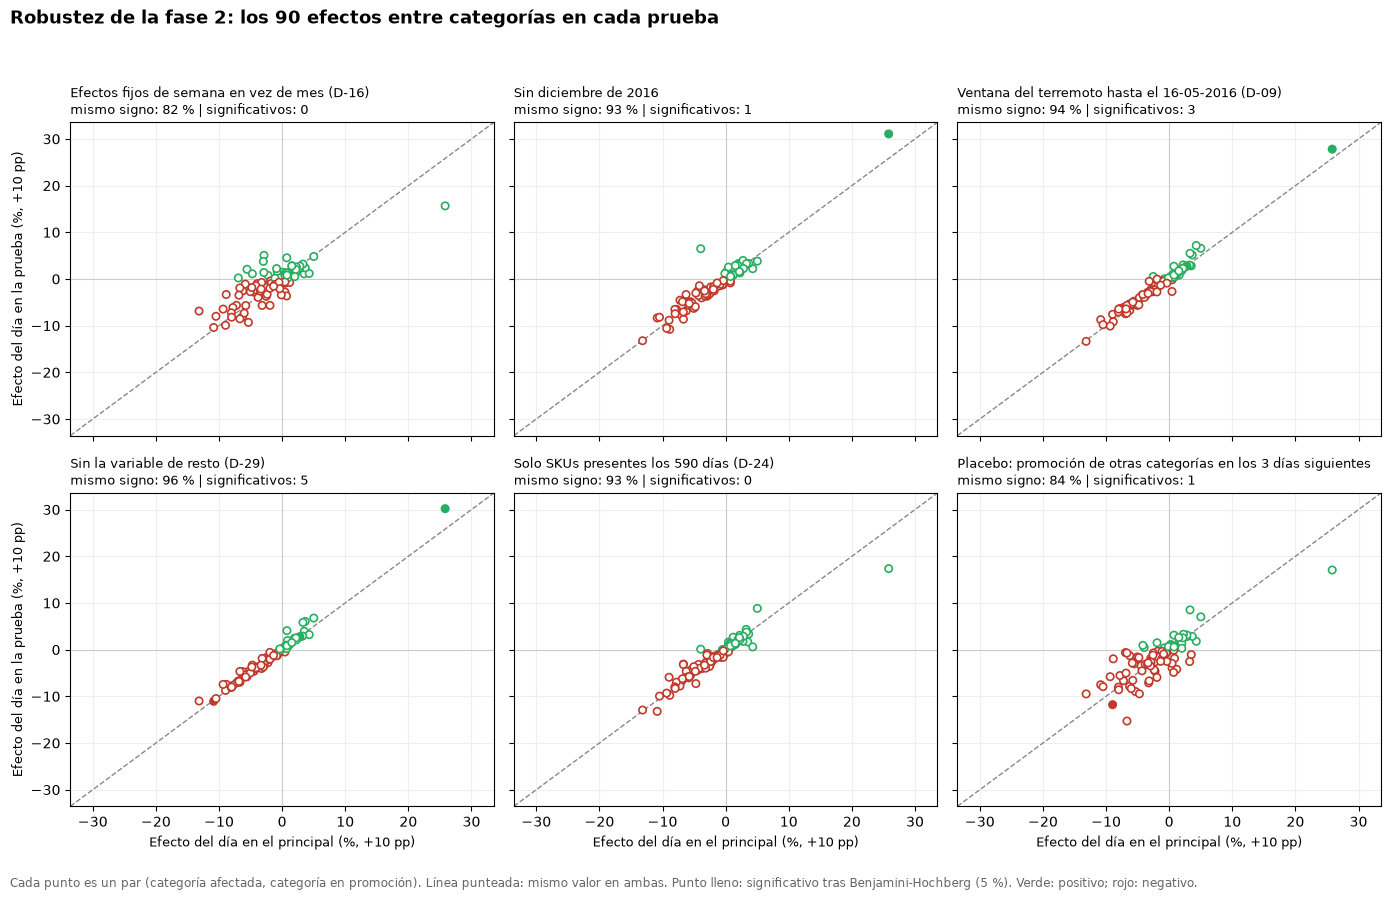

In [14]:
pruebas = [e for e in especificaciones if e not in ("principal", "intensidad_log")]
d = consistencia.loc[consistencia["bloque"] == "dia"]
fig, ejes = plt.subplots(2, 3, figsize=(14, 9), sharex=True, sharey=True)
limite = np.nanmax(np.abs(d[["efecto_pct", "efecto_pct_principal"]].to_numpy())) * 1.08
for eje, especificacion in zip(ejes.ravel(), pruebas):
    de = d.loc[d["especificacion"] == especificacion]
    color = np.where(de["efecto_pct"] > 0, "#27ae60", "#c0392b")
    eje.scatter(de["efecto_pct_principal"], de["efecto_pct"], s=28, edgecolors=color,
                facecolors=np.where(de["significativo"], color, "white"), linewidths=1.2, zorder=3)
    eje.plot([-limite, limite], [-limite, limite], color="#888888", linewidth=1, linestyle="--")
    eje.axhline(0, color="#cccccc", linewidth=0.8)
    eje.axvline(0, color="#cccccc", linewidth=0.8)
    eje.set_xlim(-limite, limite)
    eje.set_ylim(-limite, limite)
    signo = 100 * de["mismo_signo"].mean()
    eje.set_title(f"{especificaciones[especificacion]}\nmismo signo: {signo:.0f} % | significativos: {int(de['significativo'].sum())}",
                  fontsize=9.5, loc="left")
    eje.grid(color="#eeeeee")
for eje in ejes[-1]:
    eje.set_xlabel("Efecto del día en el principal (%, +10 pp)", fontsize=9)
for eje in ejes[:, 0]:
    eje.set_ylabel("Efecto del día en la prueba (%, +10 pp)", fontsize=9)
fig.suptitle("Robustez de la fase 2: los 90 efectos entre categorías en cada prueba", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.text(0.01, 0.005, "Cada punto es un par (categoría afectada, categoría en promoción). Línea punteada: mismo valor en "
         "ambas. Punto lleno: significativo tras Benjamini-Hochberg (5 %). Verde: positivo; rojo: negativo.",
         fontsize=8.5, color="#666666")
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
fig.savefig(os.path.join(ruta_figuras, f"{prefijo}_dispersion.png"), dpi=300, bbox_inches="tight")
plt.show()

## Paso 11. Exportación

In [15]:
salidas = {
    "coeficientes": coeficientes, "consistencia": consistencia, "resumen": resumen, "nuevos_significativos": nuevos,
    "placebo": placebo, "bh10": bh, "muestras": muestras, "diagnostico": diagnosticos,
}
for nombre, tabla in salidas.items():
    tabla.to_csv(os.path.join(ruta_tablas, f"{prefijo}_{nombre}.csv"), index=False)
    print(f"Guardado: {os.path.join(ruta_tablas, f'{prefijo}_{nombre}.csv')}")
print(f"Guardado: {os.path.join(ruta_figuras, f'{prefijo}_dispersion.png')}")

Guardado: resultados\tablas\robustez_fase2_coeficientes.csv
Guardado: resultados\tablas\robustez_fase2_consistencia.csv
Guardado: resultados\tablas\robustez_fase2_resumen.csv
Guardado: resultados\tablas\robustez_fase2_nuevos_significativos.csv
Guardado: resultados\tablas\robustez_fase2_placebo.csv
Guardado: resultados\tablas\robustez_fase2_bh10.csv
Guardado: resultados\tablas\robustez_fase2_muestras.csv
Guardado: resultados\tablas\robustez_fase2_diagnostico.csv
Guardado: resultados\figuras\robustez_fase2_dispersion.png


## Paso 12. Lectura automática para la tesis

Frases generadas desde las tablas: ninguna cifra está escrita a mano.

In [16]:
print("RESUMEN DE ROBUSTEZ DE LA FASE 2\n")
p_dia = resumen.loc[resumen["bloque"] == "dia"]
print(f"Efectos del día (90 pares). En el principal hay {int(p_dia['significativos_principal'].iloc[0])} pares significativos.")
for fila in p_dia.itertuples():
    if fila.especificacion == "placebo_adelanto":
        continue
    extra = "" if np.isnan(fila.mediana_abs_diferencia_pp) else f"; cambio típico {fila.mediana_abs_diferencia_pp:.1f} pp"
    print(f"  - {especificaciones[fila.especificacion]}: {int(fila.significativos)} pares significativos; misma "
          f"clasificación en {fila.pct_misma_conclusion:.0f} %; mismo signo en {fila.pct_mismo_signo:.0f} %{extra}.")

dia_nuevos = nuevos.loc[nuevos["bloque"] == "dia"]
if len(dia_nuevos):
    print("\nPares del día que cambian de clasificación en alguna prueba:")
    for (j, k), g in dia_nuevos.groupby(["categoria_afectada_j", "categoria_en_promocion_k"]):
        detalle = "; ".join(f"{especificaciones[r.especificacion]}: {r.clasificacion} ({r.efecto_pct:+.1f} %)" for r in g.itertuples())
        print(f"  - {k} -> {j}: {detalle}.")
else:
    print("\nNingún par del día cambia de clasificación: la conclusión 'sin efecto detectable' es robusta.")

print(f"\nPlacebo: {int(placebo['significativo'].sum())} de {len(placebo)} adelantos significativos tras la corrección "
      f"({int((placebo['p_valor'] < alfa).sum())} sin corregir; ~{alfa * len(placebo):.0f} esperados por azar).")
b = bh.loc[bh["bloque"] == "dia"]
print(f"Benjamini-Hochberg al 10 % (día): {int(b['significativo_5'].sum())} -> {int(b['significativo_10'].sum())} pares significativos.")
print(f"\nModelos estimados: {int(muestras['estimado'].sum())} de {len(muestras)}.")
for fila in muestras.loc[~muestras["estimado"]].itertuples():
    print(f"No estimado: {fila.especificacion} · {fila.categoria}: {fila.motivo}")
for fila in diagnosticos.itertuples():
    causa = ("varianza en dos vías negativa" if fila.varianza_dos_vias < 0 else
             "salió del modelo" if not fila.en_el_modelo else "otra causa (revisar)")
    print(f"Sin error estándar: {especificaciones[fila.especificacion]} · {fila.categoria} · {fila.variable} -> {causa} "
          f"(varía en {fila.semanas_distinto_de_cero} de {fila.semanas_total} semanas y {fila.skus_distinto_de_cero} SKUs)")
if len(no_estimables):
    print(f"Efectos no estimables (excluidos de la corrección y de las comparaciones): {len(no_estimables)}.")
print("\n>>>> Proceso finalizado <<<<")

RESUMEN DE ROBUSTEZ DE LA FASE 2

Efectos del día (90 pares). En el principal hay 0 pares significativos.
  - Efectos fijos de semana en vez de mes (D-16): 0 pares significativos; misma clasificación en 100 %; mismo signo en 82 %; cambio típico 1.3 pp.
  - Sin diciembre de 2016: 1 pares significativos; misma clasificación en 99 %; mismo signo en 93 %; cambio típico 0.7 pp.
  - Ventana del terremoto hasta el 16-05-2016 (D-09): 3 pares significativos; misma clasificación en 97 %; mismo signo en 94 %; cambio típico 0.4 pp.
  - Intensidad de otras categorías como log(1+N) (D-07): 2 pares significativos; misma clasificación en 98 %; mismo signo en 92 %.
  - Sin la variable de resto (D-29): 5 pares significativos; misma clasificación en 94 %; mismo signo en 96 %; cambio típico 0.2 pp.
  - Solo SKUs presentes los 590 días (D-24): 0 pares significativos; misma clasificación en 100 %; mismo signo en 93 %; cambio típico 0.4 pp.

Pares del día que cambian de clasificación en alguna prueba:
  - PR

## Paso 13. Cómo reportar estos resultados 

**Dónde va.** En la sección "Análisis de robustez", después de la de la fase 1: la figura `robustez_fase2_dispersion.png`, la tabla resumen y el resultado del placebo.

**Estructura sugerida** (completar con el Paso 12):

1. **Qué se hizo.** "Se reestimó el modelo de la fase 2 cambiando, una a la vez, seis decisiones previstas en la metodología [lista] y se aplicó una prueba placebo con la promoción de los tres días siguientes de cada categoría."
2. **Resultado general.** Cuántos pares son significativos en cada prueba frente al principal, y qué tan estables son los signos.
3. **Excepciones.** Los pares que cambian de clasificación (Paso 7): en qué prueba y con qué signo. Un par que aparece en varias pruebas con el mismo signo merece mención como posible efecto que el principal no alcanza a detectar.
4. **Placebo.** Si se supera, refuerza que los efectos del día no reflejan promociones anunciadas o planificadas.
5. **Conclusión.** Si la ausencia de efectos significativos entre categorías se mantiene, se reporta como un resultado **robusto de no detección** (no como ausencia demostrada de efectos: los intervalos siguen siendo amplios).

**Cuidados:** en las columnas de MEATS, POULTRY, DELI y PRODUCE se habla de promociones **fuera del programa**; "sin efecto detectable" no es "efecto nulo"; `p__RESTO` es un control y no se interpreta; actualizar la limitación "Sin análisis de robustez" de `metodologia.tex`.

*Escriban aquí su interpretación.*